# Cover Page and Intro

Student ID No: 220002931

Module Code: GG4257

Assignment: Lab Assignment 2

Github Link: https://github.com/sambowyergis/UAAssignment2 

Deadline Date: 12/11/2026

Data Link: https://drive.google.com/drive/folders/1Ux6RC3hv9DbQKutmBfzp88E18yAm2ePs?usp=sharing
<br>
To use data, place the data folder in the same folder and at the same level as the notebook

# Lab 4

## Challenge 1:

Link: https://arcg.is/1vL4ai2

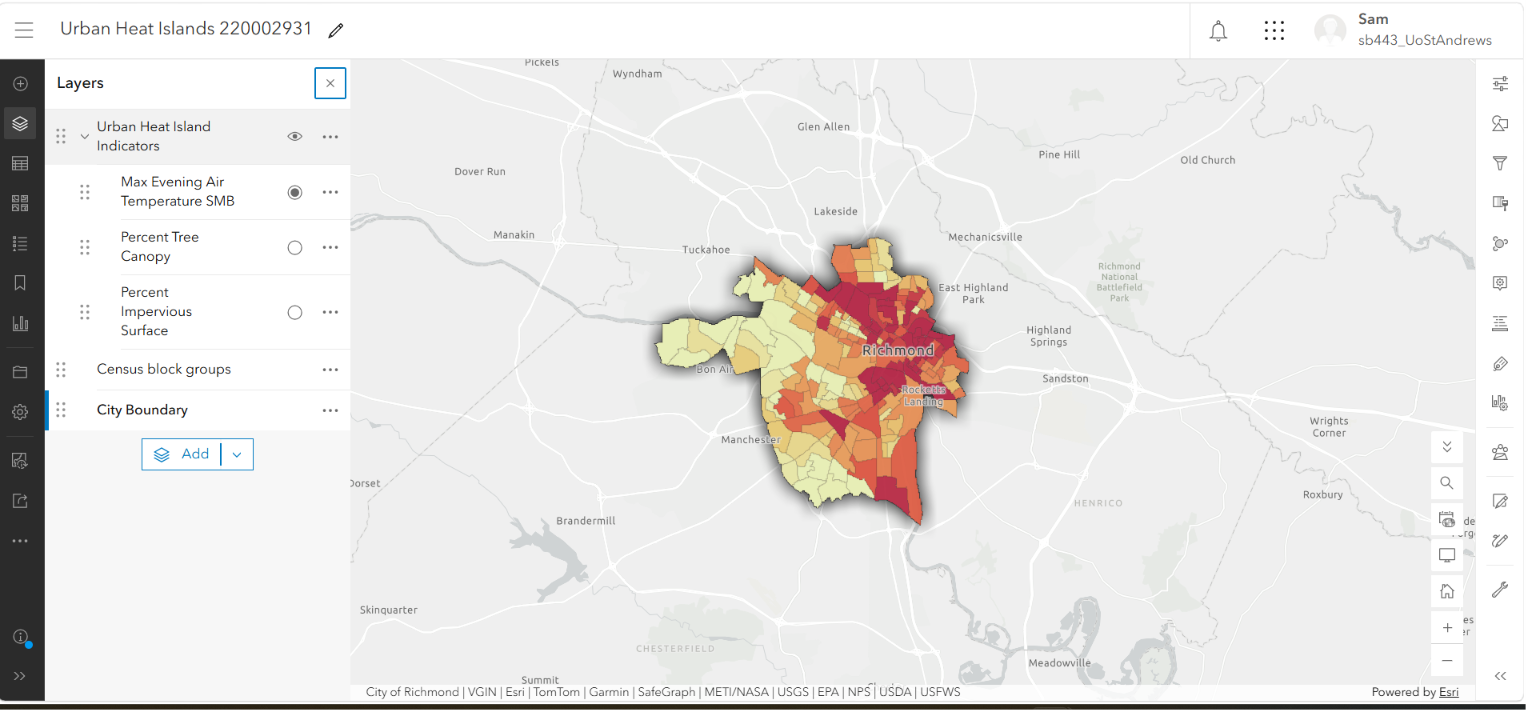

## Challenge 2:

Create two static choropleth maps (e.g. matplotlib). These maps should represent an attribute you find interesting in the SIMD dataset. Using two different classifier methods, you need to show how the maps appear different even though the data and attributes are the same. Include a clear description of your choice and the difference in the classification method for the attribute chosen (e.g. Plotting histograms with breakpoints(bins)). You can find a complete list of classifiers at https://pysal.org/mapclassify/api.html.

In [ ]:
import geopandas as gpd
import pandas as pd
import plotly.express as px
from shapely.geometry import Polygon
import requests
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns
shapefile_path = 'data/SG_SIMD_2020.shp'
gdf = gpd.read_file(shapefile_path) #import data
gdf.set_index('DataZone', inplace=True)
gdf.head()

In [ ]:
gdf["LAName"].value_counts().head(50)

In [ ]:
gdf_edi = gdf[gdf["LAName"] == "City of Edinburgh"] #exclude unwanted areas by LAname
gdf_edi.head()

In [ ]:
gdf_edi = gdf_edi.to_crs('epsg:4326')

In [ ]:
num_classes = 10 #define the number of breaks I want
classifier_nb = mc.NaturalBreaks(gdf_edi['CrimeRate'], k=num_classes)
classifier_ei = mc.EqualInterval(gdf_edi['CrimeRate'], k=num_classes) # define two different methods of grouping
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

gdf_edi.plot(column='CrimeRate', ax=axs[0], #plot results
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_nb.bins}
        )

axs[0].set_title("Choropleth Map with Natural Breaks")

gdf_edi.plot(column='CrimeRate', ax=axs[1],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins})

axs[1].set_title("Choropleth Map with Equal Intervals")

plt.tight_layout() #Optional but useful.
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5)) # create histograms to look at how my data is plotted

# 2. Same as I explained before., but one extra property, ax=axes[0], which means it is a matrix of 1 row, two columns.
sns.histplot(data=gdf_edi, x="CrimeRate", ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_nb.bins[0], color='red', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb.bins:
    axes[0].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[0].set_title("Crimerate Histogram with Natural Breaks")
axes[0].legend()

# 3. The next plot using now ax=axes[1]
sns.histplot(data=gdf_edi, x="CrimeRate", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_ei.bins[0], color='blue', linestyle='dashed', linewidth=2, label='Equal Intervals')
for bin_value in classifier_ei.bins:
    axes[1].axvline(bin_value, color='blue', linestyle='dashed', linewidth=2)
axes[1].set_title("CrimeRate Histogram with Equal Intervals")
axes[1].legend()

# 4. Adjust the plot.
plt.tight_layout()
plt.show()

Finally, create other two interactive maps (e.g. choropleth_map) - one for Glasgow and one for Edinburgh - to represent the difference in deprivation for both cities. Pick any of the available attributes., what is relevant is you can visualise how different both scottish cities are.

In [ ]:
fig = px.choropleth_map(gdf_edi, #time for the interactive maps.
                           geojson=gdf_edi.geometry,
                           locations=gdf_edi.index,
                           color="Decilev2",
                           color_continuous_scale="viridis",
                           range_color= (1, 15),
                           opacity=0.5,
                           center={"lat": 55.953251, "lon": -3.188267},
                           map_style="carto-positron",
                           zoom=9)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

In [ ]:
gdf_edi.explore(column='HouseRank', tooltip=False)

In [ ]:
shapefile_path = 'data/SIMD_2020_GlasgowCity.shp' #import glasgows data
gdf2 = gpd.read_file(shapefile_path)
gdf2.set_index('DataZone', inplace=True)
gdf2.head()

In [ ]:
gdf2.columns

In [ ]:
fig = px.choropleth_map(gdf2, #make the glasgow interactives
                           geojson=gdf2.geometry,
                           locations=gdf2.index,
                           color="Decilev2",
                           color_continuous_scale="viridis",
                           range_color= (1, 15),
                           opacity=0.5,
                           center={"lat": 55.866193, "lon": -4.258246},
                           map_style="carto-positron",
                           zoom=9.5)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

In [ ]:
gdf2 = gdf2.set_crs('epsg:4326')
gdf2.explore(column='HouseRank', tooltip=False)

# Lab 5

## Challenge 1

In [ ]:
import osmnx as ox
import networkx as nx
import numpy as np
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

key provided: eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6IjEyOTNhYjIzOTkyODQ4OTg5NmQ0ZmQ1YmVhNjM1OWFiIiwiaCI6Im11cm11cjY0In0=

In [ ]:
API_KEY = getpass.getpass("Paste your ohsome API key:")

In [ ]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/" #defien API for data
BBOX = [-4.272308, 55.855765, -4.238663, 55.869726]          # Glasgow city centre

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here with a message if something went wrong
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

### similar patterns revealed with large spike in buildings on map. Residential streets is also quite jumpy so could be unreiliable

## Challenge 2

### Firstly need to rerun code to bring shops back in for comparison.

In [ ]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

shops = dundee_services[dundee_services["service"] == "Food shop"].copy()
shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)

nearest = nx.multi_source_dijkstra_path_length(G, set(shops["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest food shop"})
shops.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest food shop (black dots = shops)")
ax.set_axis_off()
BETA = 0.069 #beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for shop_node in shops["node"]:
    distances = nx.single_source_dijkstra_path_length(G, shop_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: food shops within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score")
for ax in axes:
    ax.set_axis_off()

### Now into the challenge

In [ ]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("data/dundee_services.gpkg").to_crs("EPSG:27700") # define services
print(dundee_services["service"].value_counts())

School = dundee_services[dundee_services["service"] == "School"].copy()
print(len(nodes), "street junctions and", len(School), "School")

In [ ]:
School["node"] = ox.distance.nearest_nodes(G, School.geometry.x, School.geometry.y) #define schools
School[["name", "node"]].head()

In [ ]:
nearest = nx.multi_source_dijkstra_path_length(G, set(School["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest School"})
School.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest School (black dots = shops)")
ax.set_axis_off()
plt.show()

In [ ]:
BETA = 0.069 #beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for School_node in School["node"]:
    distances = nx.single_source_dijkstra_path_length(G, School_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: School within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score")
for ax in axes:
    ax.set_axis_off()
plt.show()

In [ ]:
BETA = 0.14 #beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for School_node in School["node"]:
    distances = nx.single_source_dijkstra_path_length(G, School_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: School within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score")
for ax in axes:
    ax.set_axis_off()
plt.show()

## Challenge 3

In [ ]:
import overturemaps

DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

print(len(places), "Overture places in Dundee")

In [ ]:
places = gpd.read_file("data/dundee_overture_places.gpkg").to_crs("EPSG:27700")
print(len(places), "Overture places in Dundee (saved copy)")

In [ ]:
places["basic_category"].value_counts().head(50)

In [ ]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False) #choose appropriate words for finding food stores
overture_shops = places[is_food & (places["confidence"] >= 0.8)].copy()

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

changes from 121 to 90^

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
shops.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_shops.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Food shops in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

In [ ]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

In [ ]:
nodes["difference"] = nodes["nearest_min_overture"] - nodes["nearest_min"]

ax = nodes.plot(column="difference", cmap="RdBu_r", vmin=-5, vmax=5, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Overture minus OSM (minutes): red = Overture further, blue = closer", "shrink": 0.7})
ax.set_title("Where the two sources disagree")
ax.set_axis_off()
plt.show()

In [ ]:
is_school = places["basic_category"].str.contains("university|school|education", na=False)
overture_school = places[is_school & (places["confidence"] >= 0.8)].copy()

print(overture_school["basic_category"].value_counts())
print()
print("schools in OpenStreetMap:", len(School))
print("schools in Overture:     ", len(overture_school))

## Challenge 4

In [ ]:
PERTH = (56.3960, -3.4370)       # Originally this was Glasgow West End, but to make it easier to find a location, we have moved the study area to Perth.
AREA = 1500                        # metres: the neighbourhood area we study, also to reflect the 15-minute neighbourhood concept (15 minutes walking = 1200 metres, 20 minutes cycling = 5000 metres)
WALK_LIMIT = 800                  # 15 minutes walking
BIKE_LIMIT = 5000                  # 20 minutes cycling

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [ ]:
G_walk = ox.load_graphml("data/perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

G_bike = ox.load_graphml("data/perth_bike.graphml")
G_bike = ox.project_graph(G_bike, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walk), "junctions | Bike network:", len(G_bike), "junctions")

In [ ]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file("data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes), "residential junctions in the neighbourhood")

In [ ]:
services = gpd.read_file("data/perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bike, homes.geometry.x, homes.geometry.y)   # the same homes on the bike network

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bike, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bike, set(bike_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    homes[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

In [ ]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 10-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 20-min cycle"] = [(homes[s + " bike (m)"] <= BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

In [ ]:
homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 15-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 15-minute neighbourhood?")
ax.set_axis_off()
plt.show()

print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

1979 residential junctions reach all 5 services on foot

## Challenge  5

In [ ]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [ ]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:27700").plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]
for name, colour in zip(SERVICES, ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

In [ ]:
home_bike = ox.distance.nearest_nodes(G_bike, centre.x.iloc[0], centre.y.iloc[0])
walk_shape = isochrone(G_walk, home, WALK_LIMIT)
bike_shape = isochrone(G_bike, home_bike, BIKE_LIMIT)

fig, ax = plt.subplots(figsize=(9, 9))
gpd.GeoSeries([bike_shape], crs="EPSG:27700").plot(ax=ax, color="#ddd2e8")
gpd.GeoSeries([walk_shape], crs="EPSG:27700").plot(ax=ax, color="#00539B")
ax.set_title("15-minute walk (blue) vs 20-minute cycle (purple)")
ax.set_axis_off()
plt.show()

print(f"Cycling reaches {bike_shape.area / walk_shape.area:.0f} times the area of walking")

In [ ]:
School = services[services["service"] == "School"]
School_nodes = set(ox.distance.nearest_nodes(G_walk, School.geometry.x, School.geometry.y))
dist_to_School = nx.multi_source_dijkstra_path_length(G_walk, School_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_School)) & walk_edges["v"].isin(set(dist_to_School))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
School.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of healthcare (red); gaps in grey")
ax.set_axis_off()
plt.show()

Largest gaps present within the NW and SE of the city centre circle as well as on the eastern side in general and especually the NE area.

## Challenge 6

In [ ]:
CITY = "Leuven, Belgium" #struggle to get other cities to work
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)
print(len(parks), "parks and", len(buildings), "buildings in", CITY)

In [ ]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
demand.head()

In [ ]:
CATCHMENT = 1200  
reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
homes_city["park_access"].describe().round(0)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

## Challenge 7

Data (Parts 3 and 6): within DIST = 2000 metres of your centre, download
the walk network with ox.graph_from_point(...)
parks ({"leisure": "park"}) and buildings ({"building": True}) with ox.features_from_point(...)
services from Overture with overturemaps.record_batch_reader(...): at least two types, e.g. food shops, healthcare and schools


In [ ]:
import geopandas as gpd
import pandas as pd
import osmnx as ox
import networkx as nx
import numpy as np
CITY = "De Pijp, Amsterdam"
WALK_SPEED = 80
DIST = 2000
CENTRE = (52.3540, 4.8930)
crs = ("EPSG:28992")
G_walk = ox.load_graphml("data/amsterdam_walk.graphml") #Data not downloaded due to limitations
G_walk = ox.project_graph(G_walk, to_crs="EPSG:28992")            
nodes, edges = ox.graph_to_gdfs(G_walk)

parks = gpd.read_file("data/amsterdam_parks.gpkg").to_crs(crs)
parks["area_m2"] = parks.area

buildings = gpd.read_file("data/amsterdam_buildings.gpkg").to_crs(crs)
print(len(parks), "parks and", len(buildings), "buildings in", G_walk)

In [ ]:
places = gpd.read_file("data/amsterdam_overture_places.gpkg").to_crs("EPSG:28992")
print(len(places), "Overture places in Amsterdam (saved copy)")

In [ ]:
places["basic_category"].value_counts().head(25)

In [ ]:
grocery = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False) #choose appropriate words for finding grocery stores
overture_grocery = places[grocery & (places["confidence"] >= 0.5)].copy()

print(overture_grocery["basic_category"].value_counts())
print()
print("Food shops in Overture:     ", len(overture_grocery))

In [ ]:
healthcare = places["basic_category"].str.contains("health|hospital|pharmacy|drug|apothecary", na=False) #appropriate words for pharmacy/medical dispensarys.
overture_health = places[healthcare & (places["confidence"] >= 0.5)].copy()

print(overture_health["basic_category"].value_counts())
print()
print("health in Overture:     ", len(overture_health))

2. **Isochrones** (Part 5): draw the 5, 10 and 15-minute walks from the centre of your neighbourhood. Show the services inside, and count how many of each type each isochrone contains.

In [ ]:
def isochrone(G_walk, start_node, metres): #make the isochrone
    reachable = nx.ego_graph(G_walk, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [ ]:
centre = gpd.GeoSeries.from_xy([CENTRE[1]], [CENTRE[0]], crs= "EPSG:4326" ).to_crs("EPSG:28992") #ensure centre is defined with correct crs
neighbourhood = centre.buffer(DIST).iloc[0]

In [ ]:
overture_health["service"] = "healthcare"
overture_grocery["service"] = "grocery"
services = pd.concat([overture_grocery,overture_health])
services = gpd.GeoDataFrame(services, geometry="geometry", crs="EPSG:28992") #create overture services data.

In [ ]:
from shapely.ops import unary_union
import matplotlib.pyplot as plt
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:28992").plot(ax=ax, color=colour, alpha=0.8)

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
inside = services[services.within(iso15)]
for name, colour in zip(["healthcare", "grocery"], ["#2a9d8f", "#F4C900"]):
    inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts()) #plot the isochrone map to show the 5 10 and 15 minute walk areas with different colours.

3. **2SFCA** (Part 6): calculate park space per building within a 15-minute walk, and map it for homes within **800 m** of the centre.

In [ ]:
CATCHMENT = 800
buffer = centre.buffer(CATCHMENT)
buildings = gpd.clip(
    buildings,
    buffer #define a buffer to use for the distance
)

parks["node"] = ox.distance.nearest_nodes(G_walk, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_walk, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
demand.head()

In [ ]:
reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_walk, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0 #define metres squared

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(G_walk)
park_access = {node: 0.0 for node in G_walk.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
homes_city["park_access"].describe().round(0) #buildings data used instead of homes as there is no homes data provided.

In [ ]:
import numpy as np  #plot the figure
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

4. **A summary table** with at least: number of parks, buildings and homes; median park m² per building; % of homes with no park within 15 minutes; services within a 15-minute walk of the centre.

In [ ]:
n_parks = len(parks) #define number of parks by using length of the parks data
n_parks

In [ ]:
n_buildings = len(homes_city) #similarly define buildings number
n_buildings

In [ ]:
park_metres_bld = (parks["area_m2"]/n_buildings).median() #to make it per building we have to devide by buildings
park_metres_bld

In [ ]:
n_access = (homes_city['park_access'] == 0).mean()*100 
n_access

In [ ]:
n_services = len(inside)
n_services

In [ ]:
import pandas as pd
summary_df = pd.DataFrame({
    "Column": [
        "Number of parks",
        "Number of buildings",
        "Median m squared per building",
        "Homes with no park within 15 mins (%)",
        "Services within 15 minutes walk",
    ],
    "Value": [
        n_parks, n_buildings, park_metres_bld, n_access, n_services,
    ],
})
summary_df
        
        

5. **Your Conclusions**: a markdown cell of **100 to 150 words** answering the question above. Use your maps and numbers as evidence, and mention at least **one limitations** of your analysis.

Limitations: Data was unable to be downloaded online so I had to use the data from the moodle. There was also limited detail in the buildings geopackage which meant buildings as a whole had to be used instead of the actual number of homes. This undoubtedly skews the results of the data. It can be concluded from the analyses that in Amsterdam there is an appropriate number and spread of pharmacy and groceries resulting in atleast one of each in every 5, 10 and 15 minute boundary. Parks are also very highly available with 99% of homes being within a 15 minute walk. THis is positive results for the planning department in the city and must be maintained.

# Lab 6

In [ ]:
# !pip install geopandas scikit-learn matplotlib scipy

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.precision", 2)
RANDOM_SEED = 42 

## 1. Define the main goal for the geodemographic classification (marketing, retail and service planning).

Service Support- Find where the armed forces (including veterans) community is concentrated and identify their circumstances. This allows veteren support, health, and employment services to be targeted efficiently

## 2. Look for census data from the selected city for which you would like to generate the geodemographic classification.

ONS data used for the plymouth area. preprocessing merging was not necessary due to the useful download tool provided.

In [ ]:
import pandas as pd
import geopandas as gpd
plymouth_data = pd.read_csv("data/lab6_data/merged_census_data.csv")
plymouth_data.head()

In [ ]:
shp_path = "data/lab6_data/OA_2021_EW_BGC_V2.shp" #define the shapefile path for georeferencing
gdf = gpd.read_file(shp_path) #read the shapefile
plymouth_gdf = gdf[gdf['LSOA21NM'].str.contains('plymouth', case=False, na=False)] #cut data to only that in plymouth
plymouth_gdf.head()

In [ ]:
merged_data = plymouth_gdf.merge(plymouth_data, left_on='LSOA21CD', right_on='geography code', how='left')
merged_data.head()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 8))
merged_data.plot(column="Household reference person previously served in regular UK armed forces", cmap="viridis", legend=True,
            legend_kwds={"label": "People served in UK regular armed forces", "shrink": 0.6}, ax=ax)
ax.set_axis_off()
ax.set_title("Plymouth UK armed forces members")
plt.show() #this is a sense check map to ensure georeferencing has worked before i go any further.

Descriptive Statistics Analysis - DEA

In [ ]:
merged_data['Economic activity status: Economically active (excluding full-time students)'].describe()

## 4. Identify the variables that will be crucial for effectively segmenting neighbourhoods. Evaluate how this choice may impact the classification results, including **a DEA analysis**.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt #make some plots 

attributes_to_plot = ['Household reference person previously served in reserve UK armed forces',
                      'Economic activity status: Economically active (excluding full-time students)',
                      'Number of cars or vans: No cars or vans in household',
                      'Economic activity status: Economically inactive']

plt.figure(figsize=(13, 9))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(x=merged_data[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt #check initial analyis as histograms

attributes_to_plot = ['Household reference person previously served in reserve UK armed forces',
                      'Economic activity status: Economically active (excluding full-time students)',
                      'Number of cars or vans: No cars or vans in household',
                      'Economic activity status: Economically inactive']

plt.figure(figsize=(13, 9))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(merged_data[attribute].astype(str), kde=True)
    plt.title(attribute)

plt.tight_layout()
plt.show()

In [ ]:
def calculate_percentages(dataframe, total_columns, value_columns): #create percentages for interestingg columns by finding the total too.

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
        # The data have several empty values, so you need to process them, forcing them to be a numeric or NaN value
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

# List of the corresponding totals.
total_cols = ['Household deprivation: Total: All households; measures: Value',
              'Household deprivation: Total: All households; measures: Value',
              'Household deprivation: Total: All households; measures: Value',
              'Household deprivation: Total: All households; measures: Value',
              'Household deprivation: Total: All households; measures: Value',
              'Disability: Total: All usual residents',
              'Disability: Total: All usual residents',
              'Number of cars or vans: Total: All households',
              'Number of cars or vans: Total: All households',
              'Number of cars or vans: Total: All households',
              'Number of cars or vans: Total: All households',
              'Economic activity status: Total: All usual residents aged 16 years and over',
              'Economic activity status: Total: All usual residents aged 16 years and over',
              'Total Military',
              'Total Military',
              'Total Military',
              'Total Military',
             ]
# List of the corresponding values. 
value_cols = [ 'Household deprivation: Household is not deprived in any dimension; measures: Value',
               'Household deprivation: Household is deprived in one dimension; measures: Value',
               'Household deprivation: Household is deprived in two dimensions; measures: Value',
               'Household deprivation: Household is deprived in three dimensions; measures: Value',
               'Household deprivation: Household is deprived in four dimensions; measures: Value',
               'Disability: Disabled under the Equality Act',
               'Disability: Not disabled under the Equality Act',
               'Number of cars or vans: No cars or vans in household',
               'Number of cars or vans: 1 car or van in household',
               'Number of cars or vans: 2 cars or vans in household',
               'Number of cars or vans: 3 or more cars or vans in household',
               'Economic activity status: Economically active (excluding full-time students): Unemployed',
               'Economic activity status: Economically active (excluding full-time students):In employment',
               'Household reference person has not previously served in regular or reserve UK armed forces',
               'Household reference person previously served in both regular and reserve UK armed forces',
               'Household reference person previously served in regular UK armed forces',
               'Household reference person previously served in reserve UK armed forces',
             ]

# Later we migth need to rename those columns., for now is ok...
result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

# Likely you could also do all this in Excel :D
# but what's important is you are aware of the correct total as dominator, census data can be very tricky

In [ ]:
result_dataframe.head()

In [ ]:
result_dataframe.shape #sense check all is good

In [ ]:
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False) #merge it all together into one big dataframe
concatenated_df.head()

In [ ]:
list(concatenated_df.columns) #check all columns present

In [ ]:
keep_cols= [ #define useful columns
   'OA21CD',
   'LSOA21CD',
   'LSOA21NM',
    'geometry',
    'Household deprivation: Household is not deprived in any dimension; measures: Value',
    'Household deprivation: Household is deprived in one dimension; measures: Value',
    'Household deprivation: Household is deprived in two dimensions; measures: Value',
    'Household deprivation: Household is deprived in three dimensions; measures: Value',
    'Household deprivation: Household is deprived in four dimensions; measures: Value',
    'Disability: Disabled under the Equality Act',
    'Disability: Not disabled under the Equality Act',
    'Number of cars or vans: No cars or vans in household',
    'Number of cars or vans: 1 car or van in household',
    'Number of cars or vans: 2 cars or vans in household',
    'Number of cars or vans: 3 or more cars or vans in household',
    'Economic activity status: Economically active (excluding full-time students): Unemployed',
    'Economic activity status: Economically active (excluding full-time students):In employment',
    'Household reference person has not previously served in regular or reserve UK armed forces',
    'Household reference person previously served in both regular and reserve UK armed forces',
    'Household reference person previously served in regular UK armed forces',
    'Household reference person previously served in reserve UK armed forces',
    'Household deprivation: Household is not deprived in any dimension; measures: Value_percentage',
    'Household deprivation: Household is deprived in one dimension; measures: Value_percentage',
    'Household deprivation: Household is deprived in two dimensions; measures: Value_percentage',
    'Household deprivation: Household is deprived in three dimensions; measures: Value_percentage',
    'Household deprivation: Household is deprived in four dimensions; measures: Value_percentage',
    'Disability: Disabled under the Equality Act_percentage',
    'Disability: Not disabled under the Equality Act_percentage',
    'Number of cars or vans: No cars or vans in household_percentage',
    'Number of cars or vans: 1 car or van in household_percentage',
    'Number of cars or vans: 2 cars or vans in household_percentage',
    'Number of cars or vans: 3 or more cars or vans in household_percentage',
    'Economic activity status: Economically active (excluding full-time students): Unemployed_percentage',
    'Economic activity status: Economically active (excluding full-time students):In employment_percentage',
    'Household reference person has not previously served in regular or reserve UK armed forces_percentage',
    'Household reference person previously served in both regular and reserve UK armed forces_percentage',
    'Household reference person previously served in regular UK armed forces_percentage',
    'Household reference person previously served in reserve UK armed forces_percentage'
]

plymouth_census_data = concatenated_df[keep_cols] #drop all others

In [ ]:
plymouth_census_data.head() # check it worked

In [ ]:
short_column_names = { #change column names so it is more understandable
    'OA21CD': 'OA',
    'LSOA21CD': 'LSOACode',
    'LSOA21NM': 'LSOAName',
    'geometry': 'geometry',
    'Household deprivation: Household is not deprived in any dimension; measures: Value': 'Not deprived',
    'Household deprivation: Household is deprived in one dimension; measures: Value': 'Deprived 1 dimension',
    'Household deprivation: Household is deprived in two dimensions; measures: Value': 'Deprived 2 dimension',
    'Household deprivation: Household is deprived in three dimensions; measures: Value': 'Deprived 3 dimension',
    'Household deprivation: Household is deprived in four dimensions; measures: Value': 'Deprived 4 dimension',
    'Disability: Disabled under the Equality Act': 'Disabled',
    'Disability: Not disabled under the Equality Act': 'Not Disabled',
    'Number of cars or vans: No cars or vans in household': 'No cars',
    'Number of cars or vans: 1 car or van in household': '1 Car',
    'Number of cars or vans: 2 cars or vans in household': '2 Cars',
    'Number of cars or vans: 3 or more cars or vans in household': '3+ Cars',
    'Economic activity status: Economically active (excluding full-time students): Unemployed': 'Unemployed',
    'Economic activity status: Economically active (excluding full-time students):In employment': 'Employed',
    'Household reference person has not previously served in regular or reserve UK armed forces': 'Veteran RorR',
    'Household reference person previously served in both regular and reserve UK armed forces': 'Veteran R+R',
    'Household reference person previously served in regular UK armed forces': 'Veteran Reg',
    'Household reference person previously served in reserve UK armed forces': 'Veteran Res',
    'Household deprivation: Household is not deprived in any dimension; measures: Value_percentage': 'Not deprived %',
    'Household deprivation: Household is deprived in one dimension; measures: Value_percentage': 'Deprived 1 %',
    'Household deprivation: Household is deprived in two dimensions; measures: Value_percentage': 'Deprived 2 %',
    'Household deprivation: Household is deprived in three dimensions; measures: Value_percentage': 'Deprived 3 %',
    'Household deprivation: Household is deprived in four dimensions; measures: Value_percentage': 'Deprived 4 %',
    'Disability: Disabled under the Equality Act_percentage': 'Disabled %',
    'Disability: Not disabled under the Equality Act_percentage': 'Not Disabled %',
    'Number of cars or vans: No cars or vans in household_percentage': 'No cars %',
    'Number of cars or vans: 1 car or van in household_percentage': '1 Car %',
    'Number of cars or vans: 2 cars or vans in household_percentage': '2 Cars %',
    'Number of cars or vans: 3 or more cars or vans in household_percentage': '3+ Cars %',
    'Economic activity status: Economically active (excluding full-time students): Unemployed_percentage': 'Unemployed %',
    'Economic activity status: Economically active (excluding full-time students):In employment_percentage': 'Employed %',
    'Household reference person has not previously served in regular or reserve UK armed forces_percentage': 'Veteran RorR %',
    'Household reference person previously served in both regular and reserve UK armed forces_percentage': 'Veteran R+R %',
    'Household reference person previously served in regular UK armed forces_percentage': 'Veteran Reg %',
    'Household reference person previously served in reserve UK armed forces_percentage': 'Veteran Res %',
}

plymouth_census_data = plymouth_census_data.rename(columns=short_column_names)

In [ ]:
plymouth_census_data.head() # check all has worked

In [ ]:
plymouth_census_data.info()

## 6. Include **standardisation between areas and variables**. Make an appropriate analysis and adjust the variable selection accordingly for any multicollinearity.

In [ ]:
numeric_columns = plymouth_census_data.select_dtypes(include='int64' and 'float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
z_score_df.head() #collect the mean for all relevent numeric and float columns

In [ ]:
z_score_df.shape

In [ ]:
corr = z_score_df.corr() #look at correlation
corr.style.background_gradient(cmap='coolwarm')

In [ ]:
import matplotlib.pyplot as plt

plt.matshow(z_score_df.corr())
plt.show()

In [ ]:
threshold = 0.7 # We can adapt this based on waht we have in our data. Recall the subjetivity issue?
# So if we include .8 then we wont be able to reduce any variables., so I took the threshold to 70%

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()

# The plot will represent  BINARY table 0 for false( out of the threshold) and 1 for above the threshold.
# but I also coloured so it is easier to use and cute :) 

In [ ]:
z_score_df.info()

In [ ]:
z_score_df.drop(['Deprived 1 %', 'Deprived 2 %', 'Deprived 3 %', 'Not Disabled %', 'No cars %', '2 Cars %', 'Unemployed %', 'Veteran RorR %'], axis=1, inplace=True)
z_score_df.info()

In [ ]:
corr_2 = z_score_df.corr()
corr_2.style.background_gradient(cmap='coolwarm')

In [ ]:
threshold = 0.7
highly_correlated_2 = (corr_2.abs() > threshold) & (corr_2.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated_2, cmap='coolwarm', cbar=False, annot=True)

plt.title('New Highly Correlated Variables')
plt.show()

Leaving in one high correlation  as they are independent variables and not similar measurements

## 5. Prepare, adjust or clean the dataset **addressing any missing values or outliers** that could distort the clustering results.

In [ ]:
contains_nan = z_score_df.isna().any().any()

if contains_nan:
    print("Oh no :( the DataFrame contains NaN values.")
else:
    print("Wahoo! the dataFrame does not contain NaN values. I'm the best")

## 8. Define the **optimum number of clusters** (i.e., using the Elblow method). Experiment with different values of k.

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist, pdist

# KMeans with 10 clusters
kmeans = KMeans(n_clusters=10) #set 10 clusters to start
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_

In [ ]:
z_score_df.head()

In [ ]:
plt.hist(labels)
# Ok, we clustered the data, but we subjectively defined the number of clusters, 
# and as you can see is one of the key parameters

In [ ]:
Sum_of_squared_distances = []

K_range = range(1,15)

for k in K_range:
 km = KMeans(n_clusters=k)
 km = km.fit(z_score_df)
 Sum_of_squared_distances.append(km.inertia_)
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

In [ ]:
import numpy as np
def elbow(dataframe, n):
    kMeansVar = [KMeans(n_clusters=k).fit(dataframe.values) for k in range(1, n)] #making use of list comprehensions.
    centroids = [X.cluster_centers_ for X in kMeansVar]
    k_euclid = [cdist(dataframe.values, cent) for cent in centroids]
    dist = [np.min(ke, axis=1) for ke in k_euclid]
    wcss = [sum(d**2) for d in dist]
    tss = sum(pdist(dataframe.values)**2)/dataframe.values.shape[0]
    bss = tss - wcss
    plt.plot(bss)
    plt.show()
 
elbow(z_score_df,15)

## 7. Utilize the **k-means** clustering algorithm to create a classification based on the selected variables.

In [ ]:
# KMeans with 5 clusters, after the validation with the Elbow method.
kmeans = KMeans(n_clusters=5)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_

z_score_df['Cluster'] = kmeans.labels_

In [ ]:
z_score_df.head()

## 9. **Evaluate your cluster groups (e.g., using PCA)** and interpret your cluster centres. Describe your results and repeat the process to adjust the variable selection and cluster groups to provide more meaningful results for your geodemographic goal. Interpret the characteristics of each cluster. **What demographic patterns or similarities are prevalent within each group?**

In [ ]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))

kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA analysys.
pca = PCA(n_components=2).fit(stand_data_scaled) #PCA with 2 components, we can also use 3 components, but for now we will use 2 to make it easier to visualize the clusters.
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

# Create a scatter plot
fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")

In [ ]:
kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

# Standardize the data for PCA
scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA
pca = PCA(n_components=2).fit(stand_data_scaled)
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=clusters, palette='viridis', s=50, alpha=0.7)
plt.title('Cluster Plot against 1st 2 Principal Components')
plt.xlabel(f'Principal Component 1 variation: {variance_ratio[0]*100:.2f}%')
plt.ylabel(f'Principal Component 2 variation: {variance_ratio[1]*100:.2f}%')
plt.legend(title='Clusters')
plt.show()

In [ ]:
# KMeans clustering
kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

# Get the cluster centers
cluster_centers = kmeans.cluster_centers_


# Get the cluster centers
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=z_score_df.columns)

# Create a new DataFrame with cluster assignments and column names
#result_df = pd.DataFrame({'Cluster': clusters, 'Column': z_score_df.columns})

cluster_centers.head(5)

In [ ]:
first_row_centers = cluster_centers.iloc[0, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

In [ ]:
first_row_centers = cluster_centers.iloc[1, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

In [ ]:
first_row_centers = cluster_centers.iloc[2, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

In [ ]:
first_row_centers = cluster_centers.iloc[3, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

In [ ]:
first_row_centers = cluster_centers.iloc[4, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

PCA 1: Two components run explain 50.365 of variance. 0 is compact. 2 and 3 overlap slightly. 1 and 4 are smaller and rather scattered.
PCA 2: This run explains 53.07% of varuance. Clusters are seperated better  and only cluster 2 overlaps with another. This is stronger.
Polar plots: The polar plots show that there are 5 clear clusters with different charachteristics and they are split well. 
cluster 0 - high rates of disability and deprivation. slightly higher in regular and reserve veterans.
cluster 1- Higher employment, car ownership, low deprivation. Average number of veterans
cluster 2- Clsoe to average on all variables.
cluster 3- High number of veterans and also highest number of car ownership rates.
cluster 4- low employment, car ownership, low veterans, above average deprived.
Limitations: THere is an issue with the polar plots having one too many points. unsure how to fix or what this is.

In [ ]:
list(z_score_df.columns)

In [ ]:
z_score_df.drop([
 'Not deprived %',
 'Deprived 4 %',
 'Disabled %',
 '1 Car %',
 '3+ Cars %',
 'Employed %',
 'Veteran R+R %',
 'Veteran Reg %',
 'Veteran Res %',], axis=1, inplace=True)
z_score_df.info()

In [ ]:
final_df = pd.concat([plymouth_census_data, z_score_df], axis=1, ignore_index=False)
final_df.head()

In [ ]:
final_df.columns

## 10. **Map the final cluster groups**

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='openstreetmap')

## 11. Finish the analysis by **naming the final clusters and plotting a final map that includes the census values and the provided names**

In [ ]:
cluster_names = {
    0: "Deprived, high disability, few cars",
    1: "Affluent working age",
    2: "Weak differentiation",
    3: "Veteran areas",
    4: "Small urban pocket",
}

final_df['Cluster'] = final_df['Cluster'].map(cluster_names)

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='openstreetmap')

## 12. Finally, acknowledge the subjective nature of classification and make analytical decisions to produce an optimum classification for your specific purpose. Reflect on the challenges and insights gained during the classification process. Ensure you document your analytical decisions and the rationale behind any important decision. Once your geodemographics are constructed, **describe the potential use cases for the geodemographic classification you have built** based on your initial goal.

Classifications are difficult to formalise. The data present can only give so much insight and there is always room for more datta especially with a secondary analysis above this initial one. During this classification process key areas for further investigation can be identified with further analysis being recommended to prove any hypothesis that may have been found. The data also is interperated and filtered in many ways through several steps through the analysis process, this measn two people working n the same project can dictate very differently the type of data present in the final output. During this classification processes it can be theorised that cluster 4 is a city centre/student filled area hence low employment. THis can be sense checked geographically but further age and gender data would need to be used to confirm this. The data even at the LSOA level oonly goes so far into providing granular data. 

For the purpose of this analysis I would suggest investigating clusters 0, 2, and 3 for further analysis as I believe these are most at risk of having deprived veterans. Cluster 3 can give insight into what services work well and where they work well whilst cluster 0 is an example of an area that needs more help. 